<a href="https://colab.research.google.com/github/kalxdoc/diabetes-ann/blob/main/diabetes_ann.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
!pip install -q ucimlrepo
import numpy as np, pandas as pd, json
from ucimlrepo import fetch_ucirepo

ds = fetch_ucirepo(id=891)               # CDC Diabetes Health Indicators
X = ds.data.features.copy()
y = ds.data.targets.iloc[:, 0].astype(int).values
print("Shape:", X.shape)
print("Features:", list(X.columns))
print("Class balance:\n", pd.Series(y).value_counts(normalize=True).round(3))
X.head()

Shape: (253680, 21)
Features: ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']
Class balance:
 0    0.861
1    0.139
Name: proportion, dtype: float64


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,1,1,1,40,1,0,0,0,0,1,...,1,0,5,18,15,1,0,9,4,3
1,0,0,0,25,1,0,0,1,0,0,...,0,1,3,0,0,0,0,7,6,1
2,1,1,1,28,0,0,0,0,1,0,...,1,1,5,30,30,1,0,9,4,8
3,1,0,1,27,0,0,0,1,1,1,...,1,0,2,0,0,0,0,11,3,6
4,1,1,1,24,0,0,0,1,1,1,...,1,0,2,3,0,0,0,11,5,4


In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

# Only ~14% of rows are class 1, so weight the classes to avoid a model that always says "0"
cw = compute_class_weight('balanced', classes=np.array([0, 1]), y=y_train)
class_weight = {0: cw[0], 1: cw[1]}
print(class_weight)

{0: np.float64(0.5809454562109614), 1: np.float64(3.5884994872157585)}


In [9]:
import tensorflow as tf
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)
ann = Sequential([
    Input(shape=(X_train_s.shape[1],)),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid'),      # binary output: P(diabetes)
])
ann.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
ann.summary()

hist2 = ann.fit(
    X_train_s, y_train,
    validation_split=0.2,
    epochs=30, batch_size=512,
    class_weight=class_weight,
    callbacks=[EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)],
    verbose=2)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │         1,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,521 (13.75 KB)

 Trainable params: 3,521 (13.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
318/318 - 3s - 9ms/step - accuracy: 0.6741 - loss: 0.5532 - val_accuracy: 0.6847 - val_loss: 0.5237
Epoch 2/30
318/318 - 2s - 5ms/step - accuracy: 0.6919 - loss: 0.5230 - val_accuracy: 0.6954 - val_loss: 0.5156
Epoch 3/30
318/318 - 2s - 6ms/step - accuracy: 0.6991 - loss: 0.5176 - val_accuracy: 0.7051 - val_loss: 0.5118
Epoch 4/30
318/318 - 2s - 7ms/step - accuracy: 0.7021 - loss: 0.5146 - val_accuracy: 0.7062 - val_loss: 0.5129
Epoch 5/30
318/318 - 2s - 7ms/step - accuracy: 0.7047 - loss: 0.5144 - val_accuracy: 0.7084 - val_loss: 0.5127
Epoch 6/30
318/318 - 3s - 9ms/step - accuracy: 0.7063 - loss: 0.5127 - val_accuracy: 0.7112 - val_loss: 0.5121
Epoch 7/30
318/318 - 3s - 10ms/step - accuracy: 0.7072 - loss: 0.5101 - val_accuracy: 0.7086 - val_loss: 0.5112
Epoch 8/30
318/318 - 4s - 14ms/step - accuracy: 0.7054 - loss: 0.5105 - val_accuracy: 0.7052 - val_loss: 0.5137
Epoch 9/30
318/318 - 4s - 11ms/step - accuracy: 0.7070 - loss: 0.5093 - val_accuracy: 0.7108 - val_loss: 0.510

25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


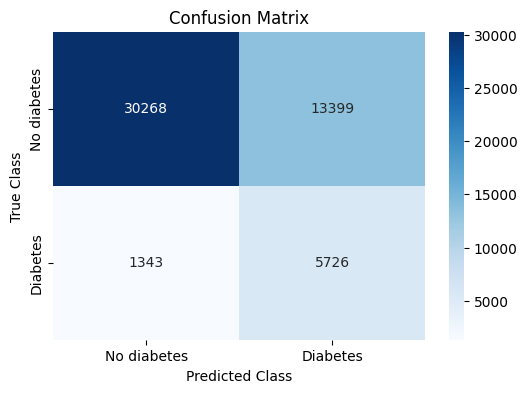

              precision    recall  f1-score   support

 No diabetes       0.96      0.69      0.80     43667
    Diabetes       0.30      0.81      0.44      7069

    accuracy                           0.71     50736
   macro avg       0.63      0.75      0.62     50736
weighted avg       0.87      0.71      0.75     50736



In [10]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

y_prob = ann.predict(X_test_s, batch_size=2048).ravel()
y_hat  = (y_prob >= 0.5).astype(int)

cm = confusion_matrix(y_test, y_hat)
labels = ['No diabetes', 'Diabetes']
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted Class'); plt.ylabel('True Class'); plt.title('Confusion Matrix')
plt.savefig('confusion_matrix_diabetes.png', dpi=150, bbox_inches='tight')
plt.show()

print(classification_report(y_test, y_hat, target_names=labels))

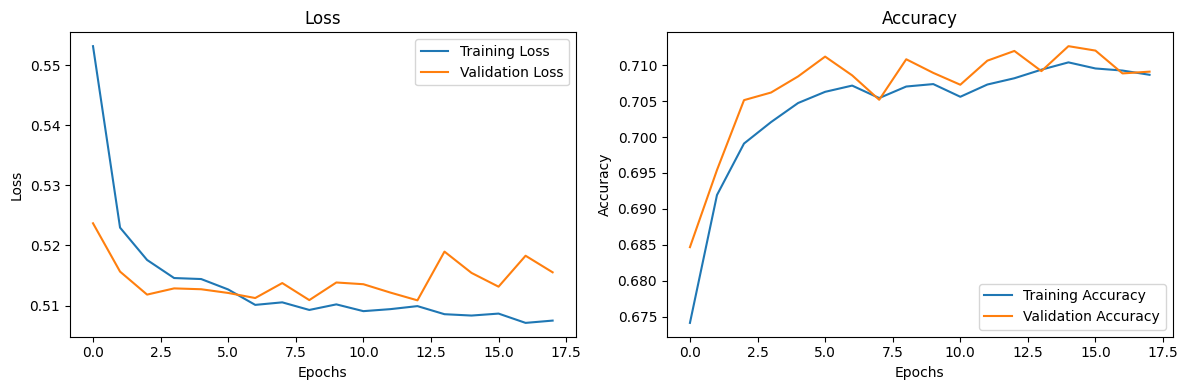

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist2.history['loss'], label='Training Loss')
axes[0].plot(hist2.history['val_loss'], label='Validation Loss')
axes[0].set_xlabel('Epochs'); axes[0].set_ylabel('Loss'); axes[0].set_title('Loss'); axes[0].legend()
axes[1].plot(hist2.history['accuracy'], label='Training Accuracy')
axes[1].plot(hist2.history['val_accuracy'], label='Validation Accuracy')
axes[1].set_xlabel('Epochs'); axes[1].set_ylabel('Accuracy'); axes[1].set_title('Accuracy'); axes[1].legend()
plt.tight_layout()
plt.savefig('loss_accuracy_diabetes.png', dpi=150, bbox_inches='tight')
plt.show()

In [12]:
import joblib
ann.save('diabetes_ann.keras')            # native Keras format (the .h5 format is legacy)
joblib.dump(scaler, 'diabetes_scaler.joblib')

# Weights as plain JSON so the website can run the ANN in the browser (no server needed)
dense = [l for l in ann.layers if isinstance(l, Dense)]
model_json = {
    "features":  list(X.columns),
    "mean":      scaler.mean_.round(6).tolist(),
    "scale":     scaler.scale_.round(6).tolist(),
    "threshold": 0.5,
    "layers": [{
        "activation": l.get_config()["activation"],
        "kernel": l.get_weights()[0].round(6).tolist(),
        "bias":   l.get_weights()[1].round(6).tolist(),
    } for l in dense],
}
json.dump(model_json, open('model.json', 'w'))

# Sanity check: reload the saved model and compare with the original
reloaded = tf.keras.models.load_model('diabetes_ann.keras')
print("Max diff after reload:", np.abs(reloaded.predict(X_test_s[:100]) - ann.predict(X_test_s[:100])).max())

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Max diff after reload: 0.0


In [13]:
HTML_TEMPLATE = r'''
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Diabetes Risk Predictor (ANN)</title>
<style>
:root{--bg:#f6f7f9;--card:#fff;--text:#1d2430;--muted:#667085;--line:#e1e5ea;--accent:#2563eb;--good:#16a34a;--bad:#dc2626}
@media (prefers-color-scheme:dark){:root{--bg:#12151a;--card:#1b2028;--text:#e8ebf0;--muted:#98a2b3;--line:#2c333d;--accent:#5b8cff;--good:#34d399;--bad:#f87171}}
*{box-sizing:border-box}
body{margin:0;background:var(--bg);color:var(--text);font:16px/1.5 system-ui,-apple-system,Segoe UI,Roboto,sans-serif}
main{max-width:860px;margin:0 auto;padding:28px 16px 48px}
h1{font-size:1.6rem;margin:0 0 4px}
p.sub{color:var(--muted);margin:0 0 20px}
.card{background:var(--card);border:1px solid var(--line);border-radius:12px;padding:20px}
.grid{display:grid;grid-template-columns:repeat(auto-fill,minmax(230px,1fr));gap:14px}
label{display:block;font-size:.85rem;color:var(--muted);margin-bottom:4px}
input,select{width:100%;padding:9px 10px;border:1px solid var(--line);border-radius:8px;background:var(--bg);color:var(--text);font:inherit}
button{margin-top:20px;width:100%;padding:12px;border:0;border-radius:8px;background:var(--accent);color:#fff;font:inherit;font-weight:600;cursor:pointer}
button:hover{opacity:.92}
#result{margin-top:20px;display:none}
.bar{height:14px;background:var(--line);border-radius:7px;overflow:hidden;margin:10px 0}
.bar>div{height:100%;width:0;transition:width .4s}
.big{font-size:1.4rem;font-weight:700}
.note{color:var(--muted);font-size:.8rem;margin-top:16px}
#err{color:var(--bad);margin-top:12px}
</style>
</head>
<body>
<main>
<h1>Diabetes Risk Predictor</h1>
<p class="sub">An ANN trained on the CDC Diabetes Health Indicators dataset. Fill in the form and press Predict.</p>
<form id="f" class="card" autocomplete="off">
  <div class="grid" id="fields"></div>
  <button type="submit">Predict</button>
  <div id="err"></div>
</form>
<div id="result" class="card">
  <div class="big" id="label"></div>
  <div class="bar"><div id="fill"></div></div>
  <div id="prob"></div>
</div>
<p class="note">Educational project, not medical advice. The model runs entirely in your browser; nothing is sent anywhere.</p>
</main>
<script>
const MODEL = /*MODEL_JSON*/null;

const YN = [[0,"No"],[1,"Yes"]];
const FIELDS = {
  HighBP:["High blood pressure",YN], HighChol:["High cholesterol",YN],
  CholCheck:["Cholesterol check in last 5 years",YN],
  BMI:["Body Mass Index (BMI)","number",10,80,27],
  Smoker:["Smoked 100+ cigarettes in lifetime",YN], Stroke:["Ever had a stroke",YN],
  HeartDiseaseorAttack:["Heart disease or heart attack",YN],
  PhysActivity:["Physical activity in past 30 days",YN],
  Fruits:["Eats fruit daily",YN], Veggies:["Eats vegetables daily",YN],
  HvyAlcoholConsump:["Heavy alcohol consumption",YN],
  AnyHealthcare:["Has health coverage",YN], NoDocbcCost:["Skipped doctor due to cost",YN],
  GenHlth:["General health",[[1,"1 - Excellent"],[2,"2 - Very good"],[3,"3 - Good"],[4,"4 - Fair"],[5,"5 - Poor"]]],
  MentHlth:["Bad mental-health days (0-30)","number",0,30,0],
  PhysHlth:["Bad physical-health days (0-30)","number",0,30,0],
  DiffWalk:["Difficulty walking or climbing stairs",YN],
  Sex:["Sex",[[0,"Female"],[1,"Male"]]],
  Age:["Age group",["18-24","25-29","30-34","35-39","40-44","45-49","50-54","55-59","60-64","65-69","70-74","75-79","80+"].map((t,i)=>[i+1,t])],
  Education:["Education",[[1,"Never attended / kindergarten"],[2,"Elementary"],[3,"Some high school"],[4,"High school graduate"],[5,"Some college"],[6,"College graduate"]]],
  Income:["Annual income",[[1,"< $10k"],[2,"$10-15k"],[3,"$15-20k"],[4,"$20-25k"],[5,"$25-35k"],[6,"$35-50k"],[7,"$50-75k"],[8,"$75k+"]]]
};
const DEFAULTS = {CholCheck:1,PhysActivity:1,AnyHealthcare:1,GenHlth:3,Age:6,Education:5,Income:6,Veggies:1};

const box = document.getElementById("fields");
const names = MODEL ? MODEL.features : Object.keys(FIELDS);
names.forEach(n=>{
  const d = FIELDS[n]; if(!d) return;
  const w = document.createElement("div");
  let h = `<label for="${n}">${d[0]}</label>`;
  if(d[1]==="number") h += `<input id="${n}" type="number" min="${d[2]}" max="${d[3]}" step="any" value="${d[4]}" required>`;
  else h += `<select id="${n}">` + d[1].map(([v,t])=>`<option value="${v}"${(DEFAULTS[n]??0)==v?" selected":""}>${t}</option>`).join("") + `</select>`;
  w.innerHTML = h; box.appendChild(w);
});

function forward(x){
  let a = x;
  for(const L of MODEL.layers){
    const out = L.bias.map((b,j)=>{ let s=b; for(let i=0;i<a.length;i++) s+=a[i]*L.kernel[i][j]; return s; });
    if(L.activation==="relu") a = out.map(v=>Math.max(0,v));
    else if(L.activation==="sigmoid") a = out.map(v=>1/(1+Math.exp(-v)));
    else if(L.activation==="softmax"){ const m=Math.max(...out), e=out.map(v=>Math.exp(v-m)), s=e.reduce((p,c)=>p+c,0); a=e.map(v=>v/s); }
    else a = out;
  }
  return a;
}
function predict(values){
  const z = MODEL.features.map((n,i)=>(values[n]-MODEL.mean[i])/MODEL.scale[i]);
  return forward(z)[0];
}
document.getElementById("f").addEventListener("submit",e=>{
  e.preventDefault();
  const err = document.getElementById("err"); err.textContent="";
  if(!MODEL){ err.textContent="No model embedded. Run the notebook's website cell to generate index.html."; return; }
  const v = {}; MODEL.features.forEach(n=>v[n]=parseFloat(document.getElementById(n).value));
  const p = predict(v), thr = MODEL.threshold ?? 0.5, high = p>=thr;
  document.getElementById("result").style.display="block";
  const lab = document.getElementById("label");
  lab.textContent = high ? "Higher diabetes risk" : "Lower diabetes risk";
  lab.style.color = high ? "var(--bad)" : "var(--good)";
  const fill = document.getElementById("fill");
  fill.style.width = (p*100).toFixed(1)+"%"; fill.style.background = high ? "var(--bad)" : "var(--good)";
  document.getElementById("prob").textContent = `Model probability: ${(p*100).toFixed(1)}% (decision threshold ${(thr*100).toFixed(0)}%)`;
});
if(typeof module!=="undefined") module.exports={predict,forward};
</script>
</body>
</html>
'''

html = HTML_TEMPLATE.replace('/*MODEL_JSON*/null', json.dumps(model_json))
open('index.html', 'w', encoding='utf-8').write(html)
print('index.html written:', round(len(html)/1024), 'KB')

index.html written: 81 KB


In [14]:
# Cross-check: the website's math (numpy re-implementation of what the JS does) vs Keras
def web_forward(row):
    a = (row - np.array(model_json['mean'])) / np.array(model_json['scale'])
    for L in model_json['layers']:
        a = a @ np.array(L['kernel']) + np.array(L['bias'])
        a = np.maximum(a, 0) if L['activation'] == 'relu' else 1/(1+np.exp(-a))
    return a[0]
row = X_test.iloc[0].values.astype(float)
print("Website:", web_forward(row), "| Keras:", float(ann.predict(X_test_s[:1])[0, 0]))

# Download the files from Colab
from google.colab import files
for f in ['index.html', 'diabetes_ann.keras', 'model.json', 'confusion_matrix_diabetes.png', 'loss_accuracy_diabetes.png']:
    files.download(f)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 240ms/step
Website: 0.525294146529467 | Keras: 0.5252942442893982


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>